In [19]:
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
df['periodo'] = pd.cut(
    df['ano'],
    bins=[1994, 1998, 2002, 2006, 2010, 2014, 2018, 2022, 2026],
    labels=[
        '1995-1998 (FHC)',
        '1999-2002 (FHC)',
        '2003-2006 (Lula)',
        '2007-2010 (Lula)',
        '2011-2014 (Dilma)',
        '2015-2018 (Dilma/Temer)',
        '2019-2022 (Bolsonaro)',
        '2023-2026 (Lula)'
    ]
)

In [21]:
resumo_periodos = df.groupby('periodo', observed=True).agg(
    assistencia_media=('investimento_assistencia_estudantil_bilhoes_brl', 'mean'),
    assistencia_mediana=('investimento_assistencia_estudantil_bilhoes_brl', 'median'),
    assistencia_soma=('investimento_assistencia_estudantil_bilhoes_brl', 'sum'),

    vagas_media=('num_vagas_estudantes', 'mean'),
    vagas_mediana=('num_vagas_estudantes', 'median'),
    vagas_soma=('num_vagas_estudantes', 'sum')
).reset_index()

print(resumo_periodos)

                   periodo  assistencia_media  assistencia_mediana  \
0          1995-1998 (FHC)           0.023333                0.020   
1          1999-2002 (FHC)           0.040000                0.040   
2         2003-2006 (Lula)           0.110000                0.100   
3         2007-2010 (Lula)           0.515000                0.515   
4        2011-2014 (Dilma)           1.142500                1.165   
5  2015-2018 (Dilma/Temer)           1.260000                1.265   
6    2019-2022 (Bolsonaro)           1.100000                1.120   
7         2023-2026 (Lula)           1.190000                1.215   

   assistencia_soma   vagas_media  vagas_mediana  vagas_soma  
0              0.07  3.521333e+05       351400.0     1056400  
1              0.16  4.016500e+05       401150.0     1606600  
2              0.44  5.073750e+05       501000.0     2029500  
3              2.06  7.711250e+05       770150.0     3084500  
4              4.57  1.076625e+06      1085000.0     4

In [22]:
resumo_periodos['assistencia_por_vaga'] = (
    resumo_periodos['assistencia_soma'] * 1_000_000_000
    / resumo_periodos['vagas_soma'].replace(0, float('nan'))
)

print(resumo_periodos[['periodo', 'assistencia_por_vaga']])

                   periodo  assistencia_por_vaga
0          1995-1998 (FHC)             66.262779
1          1999-2002 (FHC)             99.589195
2         2003-2006 (Lula)            216.802168
3         2007-2010 (Lula)            667.855406
4        2011-2014 (Dilma)           1061.186578
5  2015-2018 (Dilma/Temer)           1014.697000
6    2019-2022 (Bolsonaro)            832.860117
7         2023-2026 (Lula)            870.837907


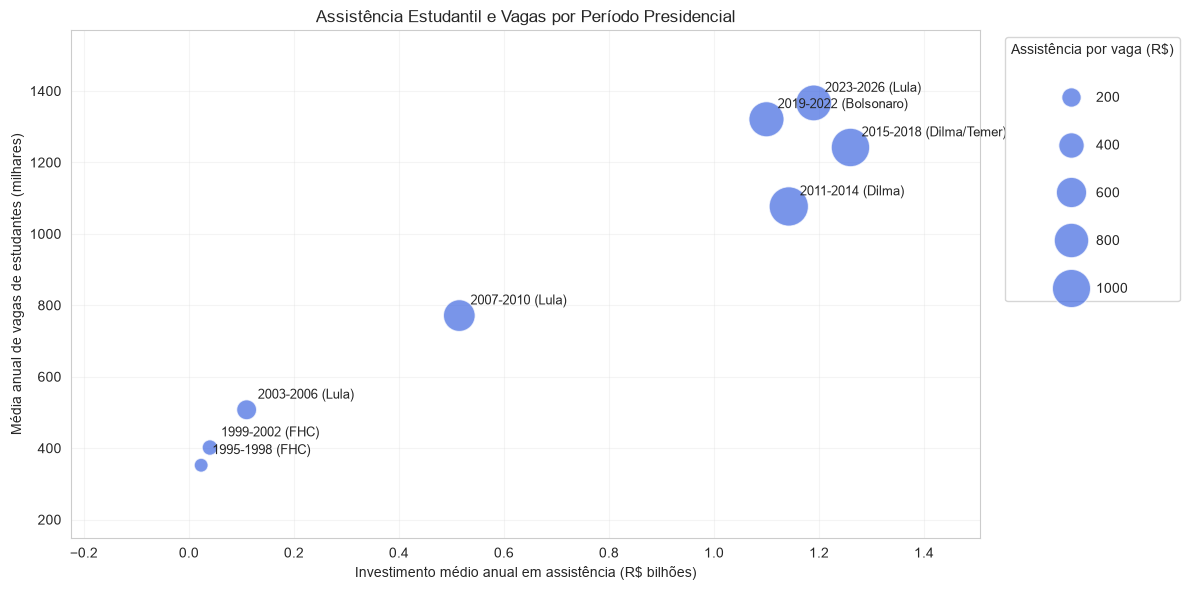

In [26]:
import seaborn as sb
import matplotlib.pyplot as plt

dados = resumo_periodos.dropna(subset=[
    'assistencia_media',
    'vagas_media',
    'assistencia_por_vaga'
]).copy()

dados['vagas_mil'] = dados['vagas_media'] / 1000

plt.figure(figsize=(12, 6))

ax = sb.scatterplot(
    data=dados,
    x='assistencia_media',
    y='vagas_mil',
    size='assistencia_por_vaga',
    sizes=(100, 800),
    color='royalblue',
    alpha=0.7,
    edgecolor='white',
    legend='brief'
)

# Identificar os períodos presidenciais
for _, linha in dados.iterrows():
    plt.annotate(
        str(linha['periodo']),
        (linha['assistencia_media'], linha['vagas_mil']),
        xytext=(8, 8),
        textcoords='offset points',
        fontsize=9
    )

plt.title('Assistência Estudantil e Vagas por Período Presidencial')
plt.xlabel('Investimento médio anual em assistência (R$ bilhões)')
plt.ylabel('Média anual de vagas de estudantes (milhares)')

ax.legend(
    title='Assistência por vaga (R$)',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    labelspacing=2.5
)

plt.grid(alpha=0.2)
plt.margins(0.2)
plt.tight_layout()
plt.show()